# Step 3 · Which model?

**Goal:** a model that predicts a recipe's cell count **and how sure it is**. We need the uncertainty later, to decide where to experiment: a recipe the model is unsure about may be worth testing.

Three candidates:

| Model | Idea | Uncertainty |
|---|---|---|
| **Average** (baseline) | Always predicts the mean of the data | The spread of the data |
| **Random forest** | Averages many decision trees, each trained on a random part of the data | How much the trees disagree (a rough proxy) |
| **Gaussian process (GP)** | Similar recipes give similar growth; the prediction for a new recipe is a weighted average of nearby measured recipes | Built in: small near measured recipes, large far away |

The GP is the standard model in Bayesian optimisation because it works with very little data and gives a principled uncertainty.

In [1]:
import warnings; warnings.filterwarnings("ignore")  # sklearn fitting chatter on tiny data
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from mediaopt.data import COLS, load_recipes
from mediaopt.model import MODELS, fit, leave_one_out, make_gp, predict, score

df = load_recipes()
gp = fit(make_gp(), df)
gp.kernel_

1.17**2 * Matern(length_scale=1.1, nu=2.5) + WhiteKernel(noise_level=0.498)

**What the GP learned** (its settings, fitted to the data):
- **Amplitude** (≈ 1.2²): how much growth typically varies between recipes.
- **Length-scale** (≈ 1.1 on the 0-1 scale): how far you can change a recipe before growth changes noticeably. One shared value for all 14 components. With only 25 recipes, a separate value per component would be guesswork.
- **Measurement noise:** we pass each recipe's measured replicate variance (`y_var`).
- **Extra noise** (≈ 0.5): variation the model can't explain beyond replicate noise. Examples are differences between experiment days, or effects too complex for 25 points. It is much larger than the replicate noise (≈ 0.05), which tells us the measurement isn't the main uncertainty; the model is.

**The GP in action:** vary FBS from 0 to 1 while keeping the other 13 components at the best recipe's values.

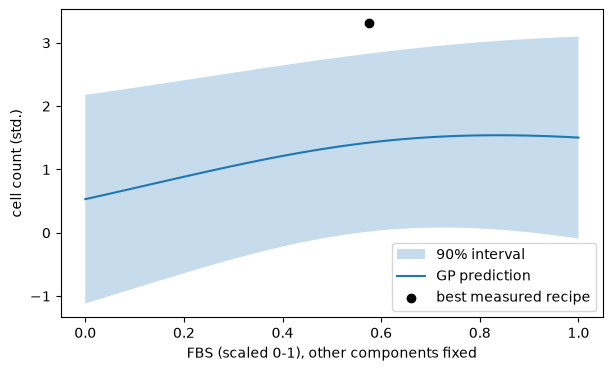

In [2]:
best = df.loc[df.y.idxmax()]
line = pd.DataFrame([best[COLS]] * 101).reset_index(drop=True)
line["FBS"] = np.linspace(0, 1, 101)
mean, sd = predict(gp, line)

plt.figure(figsize=(7, 4))
plt.fill_between(line.FBS, mean - 1.645 * sd, mean + 1.645 * sd, alpha=0.25, label="90% interval")
plt.plot(line.FBS, mean, label="GP prediction")
plt.scatter(best.FBS, best.y, color="black", zorder=3, label="best measured recipe")
plt.xlabel("FBS (scaled 0-1), other components fixed")
plt.ylabel("cell count (std.)")
plt.legend()
plt.show()

**Reading the plot:**
- **The band is wide everywhere.** 25 recipes in 14 dimensions leave the model unsure about almost any recipe. The uncertainty is the model being honest about thin data.
- **The best measured recipe (y = 3.3) lies above the band.** Because of the extra noise, the model treats part of that result as unexplained variation: it expects a repeat measurement to come out lower (*regression to the mean*). This is a cautious, reasonable view with this little data.
- Along this line the model sees a mild benefit of FBS that levels off. It is a smooth, simple model, so don't read fine detail into the curve.

## Comparing the models fairly: leave-one-out

We can't judge a model on the data it was trained on. Instead, for each of the 25 recipes:
1. Hide it.
2. Train on the other 24.
3. Predict the hidden one.

Then we compare predictions with reality:
- **RMSE:** typical size of the error (lower is better).
- **Rank correlation:** does the model put recipes in the right order? 1 = perfect, 0 = random. This matters most, because we use the model to *pick* recipes.
- **90 % interval coverage:** how often the truth falls inside the predicted 90 % interval. About 0.9 means the uncertainty is honest; much lower means over-confident.

In [3]:
results = {name: leave_one_out(model, df) for name, model in MODELS.items()}
pd.DataFrame({name: score(pred) for name, pred in results.items()}).T.round(2)

,RMSE,rank correlation,90% interval coverage
average (baseline),1.33,-1.00,0.92
random forest,1.22,0.37,0.76
Gaussian process,1.16,0.52,0.88


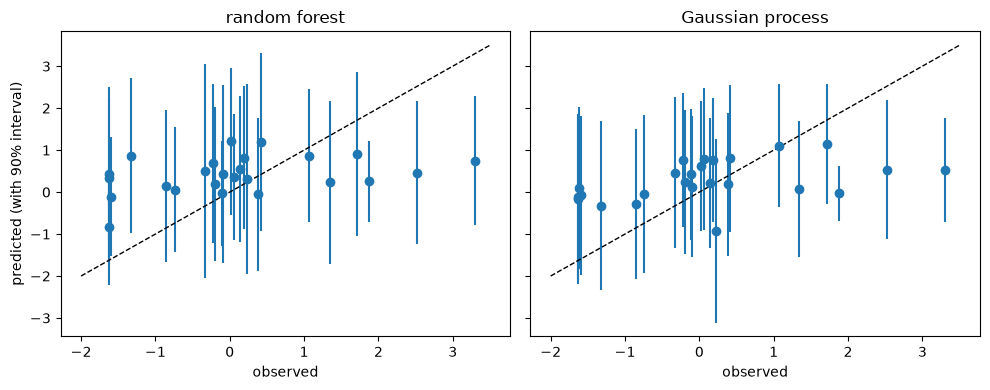

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharex=True, sharey=True)
for ax, name in zip(axes, ["random forest", "Gaussian process"]):
    p = results[name]
    ax.errorbar(p.observed, p.predicted, yerr=1.645 * p.sd, fmt="o", capsize=0)
    ax.plot([-2, 3.5], [-2, 3.5], "k--", linewidth=1)
    ax.set_title(name)
    ax.set_xlabel("observed")
axes[0].set_ylabel("predicted (with 90% interval)")
fig.tight_layout()
plt.show()

**Takeaways**
- **No model predicts well.** Typical errors (≈ 1.2) are close to the spread of the data (1.3). That is expected with 25 recipes and 14 components.
- **The GP is the best of the three on every measure:**
  - lowest error;
  - best ranking (0.52 vs 0.36 for the forest);
  - honest uncertainty (88 % coverage, against 90 % expected).
  The forest's intervals are too narrow (76 %): it is over-confident.
- **Both models under-predict the best recipes** (right side of the plots). Neither can yet tell how good the top region is. That is exactly why we won't just pick the highest prediction, but also use the uncertainty (step 4).
- The average model's rank correlation of −1.00 is meaningless: leaving a high value out lowers the average.

**Choice:** the Gaussian process, for its ranking and its honest uncertainty, which step 4 depends on.